# Microbiome Features That Stratify the Defense Score (Recalled Genera)

Looks for any aspect of the microbiome that separates samples into groups with different defense scores.

**Defense score:** the 148 load-correlated defense genes (`load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv`), z-scored across all transcriptome samples, sum / 148. This is the same score as `defense_z_score_distribution.ipynb`.

**Two versions of every test:**
- **Within timepoint:** `defense ~ timepoint + feature`. Samples are only compared with samples from the same timepoint, so seasonal trends in the microbiome and in defense don't drive the result.
- **Across the season:** `defense ~ feature`, ignoring timepoint. Picks up features that differ between high- and low-defense samples anywhere in the season, including through seasonal change.

**Features tested**
1. **Microbiome groups:** total abundance of core (> 80% seasonal prevalence), accessory, rare (< 10%) and ultra-rare (< `ultra_rare_prevalence_threshold`) genera, plus the number of rare / ultra-rare genera present, core genera missing, genus richness and Shannon diversity.
2. **Single genera:** presence vs absence, and relative abundance (% of the sample's reads), both untransformed and log-transformed (log10(% + 0.05)). The log version mostly separates samples with and without a genus, so it tends to mirror presence/absence; the untransformed version is driven more by samples where a genus is abundant.
3. **Pairs of genera:** both present vs not.
4. **Combinations, data-driven:** a shallow decision tree and a random forest on all genera and group features. Both are cross-validated holding out whole timepoints and compared with shuffled defense scores.

Ultra-rare is a stricter version of the rare definition: genera present in < 5% of seasonal samples. Total bacterial load is not accounted for here.

p-values are BH-corrected within each set of tests.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from scipy.stats import zscore
from skbio.diversity.alpha import shannon
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import r2_score

###Define Thresholds
core_prevalence_threshold = 0.8
rare_prevalence_threshold = 0.1
ultra_rare_prevalence_threshold = 0.05
min_group_size = 10  # smallest group allowed in a presence / co-presence split
min_prevalence_abundance_test = 0.2
pair_prevalence_range = (0.1, 0.9)
genus_pseudocount = 0.05  # % of reads (detection floor), for the log-transformed abundance
n_permutations = 100
random_seed = 0

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
metadata = metadata.drop(
    columns=[
        "arb.sort",
        "sample-id",
        "Ambiguous Unstranded",
        "Ambiguous Forward",
        "Multimapping",
        "Unmapped Over Mapped",
    ]
)
metadata["Date and Time"] = metadata["date"] + " " + metadata["time"]
luke_time_data_format = "%-m/%-d/%y %-H:%-M"
metadata["Date and Time"] = pd.to_datetime(
    metadata["Date and Time"], format=luke_time_data_format
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))
defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)
defense_genes = trimmed_transcriptome.loc[:, trimmed_transcriptome.columns.isin(defense_gene_list["gene"])]
trimmed_metadata["Defense Z Score"] = defense_genes.apply(zscore).sum(axis=1) / len(defense_gene_list)

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426


## Microbiome features

In [3]:
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Sept_2026_recalled_genera/lic_16S_gen_rab_clean.csv"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]
genus_abundance_matrix = pd.pivot_table(
    plant_microbiome, values="Abundance", index="Sample", columns="Genus", aggfunc="sum", fill_value=0
)
genus_abundance_matrix = genus_abundance_matrix.div(genus_abundance_matrix.sum(axis=1), axis=0) * 100

seasonal_samples = plant_microbiome.loc[plant_microbiome["seascirc"] == "seasonal", "Sample"].unique()
# Genera never seen in seasonal samples get 0% prevalence (rare and ultra-rare)
seasonal_prevalence = (genus_abundance_matrix.loc[seasonal_samples] > 0).mean().reindex(
    genus_abundance_matrix.columns, fill_value=0.0
)
genus_class = pd.Series(
    np.select(
        [
            seasonal_prevalence > core_prevalence_threshold,
            seasonal_prevalence < ultra_rare_prevalence_threshold,
            seasonal_prevalence < rare_prevalence_threshold,
        ],
        ["core", "ultra-rare", "rare"],
        default="accessory",
    ),
    index=seasonal_prevalence.index,
)
core_genera = genus_class.index[genus_class == "core"]
rare_genera = genus_class.index[genus_class.isin(["rare", "ultra-rare"])]  # all < 10%
ultra_rare_genera = genus_class.index[genus_class == "ultra-rare"]
accessory_genera = genus_class.index[genus_class == "accessory"]
print(f"Core: {len(core_genera)}, accessory: {len(accessory_genera)}, rare (< 10%): {len(rare_genera)}, "
      f"of which ultra-rare (< {ultra_rare_prevalence_threshold:.0%}): {len(ultra_rare_genera)}")

samples = trimmed_metadata.index[trimmed_metadata["sampID"].isin(genus_abundance_matrix.index)]
sample_genera = genus_abundance_matrix.loc[trimmed_metadata.loc[samples, "sampID"]].set_index(samples)
present = sample_genera > 0

group_features = pd.DataFrame(
    {
        "core total %": sample_genera[core_genera].sum(axis=1),
        "accessory total %": sample_genera[accessory_genera].sum(axis=1),
        "rare total %": sample_genera[rare_genera].sum(axis=1),
        "ultra-rare total %": sample_genera[ultra_rare_genera].sum(axis=1),
        "n rare genera present": present[rare_genera].sum(axis=1),
        "n ultra-rare genera present": present[ultra_rare_genera].sum(axis=1),
        "n core genera missing": (~present[core_genera]).sum(axis=1),
        "genus richness": present.sum(axis=1),
        "Shannon diversity": sample_genera.apply(lambda row: shannon(row.to_numpy()), axis=1),
    }
)
defense = trimmed_metadata.loc[samples, "Defense Z Score"]
timepoints = trimmed_metadata.loc[samples, "timepoint"]
timepoint_dummies = pd.get_dummies(timepoints, prefix="tp", drop_first=True, dtype=float)
print(f"Samples with transcriptome and microbiome: {len(samples)}")
group_features.describe().round(2)

Core: 36, accessory: 82, rare (< 10%): 160, of which ultra-rare (< 5%): 137
Samples with transcriptome and microbiome: 424


,core total %,accessory total %,rare total %,ultra-rare total %,n rare genera present,n ultra-rare genera present,n core genera missing,genus richness,Shannon diversity
count,424.00,424.00,424.00,424.00,424.00,424.00,424.00,424.00,424.00
mean,91.66,7.88,0.46,0.22,2.79,1.45,2.77,61.77,2.79
std,4.41,4.08,0.63,0.40,3.02,2.11,2.23,12.83,0.32
min,67.33,1.08,0.00,0.00,0.00,0.00,0.00,34.00,1.08
25%,89.59,5.03,0.07,0.00,1.00,0.00,1.00,53.00,2.61
50%,92.62,7.07,0.26,0.07,2.00,1.00,2.00,61.00,2.80
75%,94.73,9.92,0.63,0.23,4.00,2.00,4.00,69.00,2.98
max,98.92,29.92,5.22,2.97,21.00,18.00,12.00,114.00,3.76


In [4]:
def test_feature(x):
    """Coefficient of a feature on the defense score, within timepoint and across the season."""
    out = {}
    for label, covariates in [
        ("within timepoint", timepoint_dummies),
        ("across season", None),
    ]:
        X = sm.add_constant(pd.concat([covariates, x.rename("feature").astype(float)], axis=1))
        fit = sm.OLS(defense, X).fit()
        out[f"coef ({label})"] = fit.params["feature"]
        out[f"t ({label})"] = fit.tvalues["feature"]
        out[f"p ({label})"] = fit.pvalues["feature"]
    return out


def add_q(results):
    for label in ["within timepoint", "across season"]:
        results[f"q ({label})"] = multipletests(results[f"p ({label})"], method="fdr_bh")[1]
    return results


# Defense score with timepoint means removed (within timepoint), and as is (across season)
within_residual = sm.OLS(defense, sm.add_constant(timepoint_dummies)).fit().resid
defense_versions = {"within timepoint": within_residual, "across season": defense}

## 1. Microbiome groups

Each feature is tested as a continuous value; coefficients are per standard deviation of the feature. The plots split samples into quartiles of each feature: within timepoint (defense with timepoint means removed), and across the season (raw defense score).

In [5]:
group_results = pd.DataFrame(
    {name: test_feature((values - values.mean()) / values.std()) for name, values in group_features.items()}
).T
group_results = add_q(group_results)
group_results[[c for c in group_results.columns if c.startswith(("coef", "q"))]].round(4)

,coef (within timepoint),coef (across season),q (within timepoint),q (across season)
core total %,0.0262,-0.1159,0.9145,0.0003
accessory total %,-0.0239,0.1121,0.9145,0.0003
rare total %,-0.0243,0.0846,0.9145,0.0048
ultra-rare total %,-0.0112,0.0903,0.9254,0.0035
n rare genera present,-0.0107,0.1082,0.9254,0.0004
n ultra-rare genera present,0.0022,0.1210,0.9254,0.0003
n core genera missing,-0.0114,-0.0081,0.9254,0.7827
genus richness,0.0046,0.0856,0.9254,0.0048
Shannon diversity,0.0039,0.0269,0.9254,0.4041


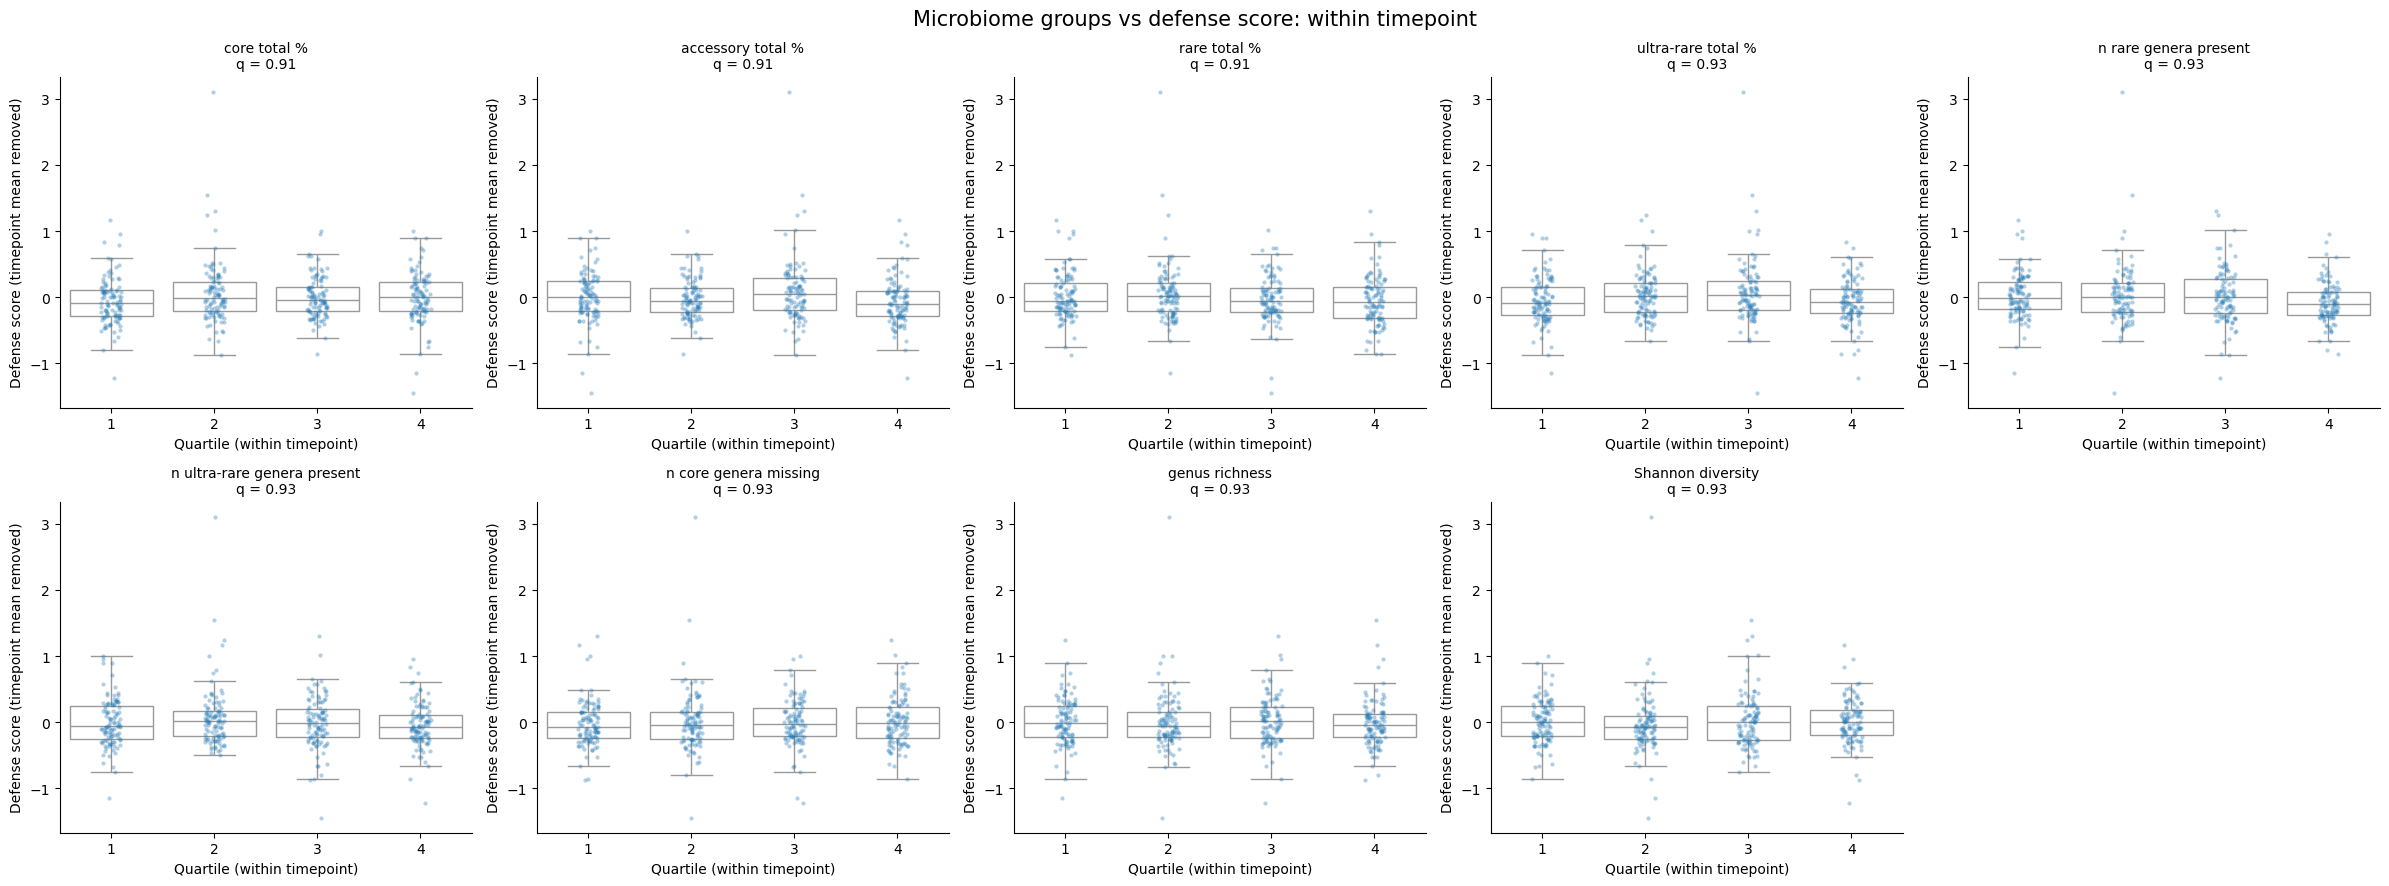

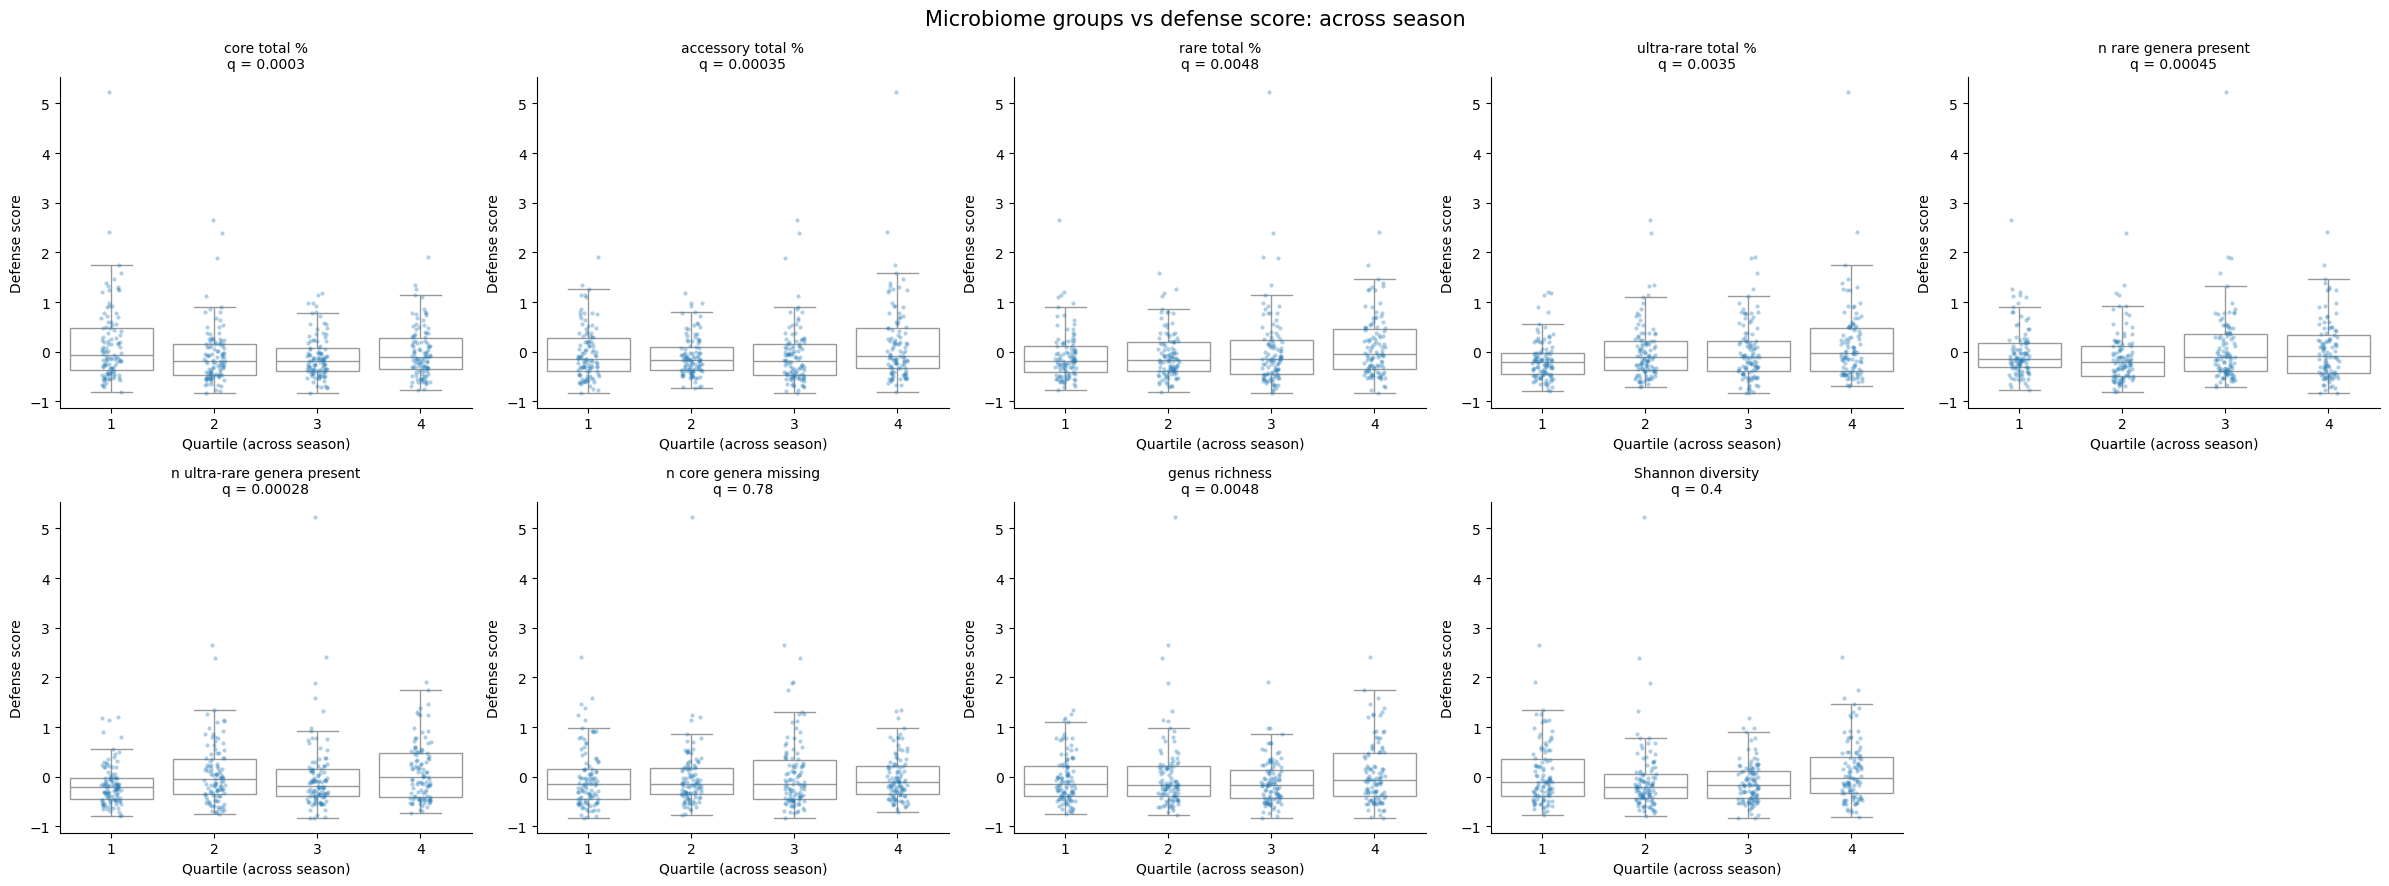

In [6]:
for mode, target in defense_versions.items():
    fig, axes = plt.subplots(2, 5, figsize=(24, 9))
    fig.patch.set_facecolor("white")
    for ax, (name, values) in zip(axes.flatten(), group_features.items()):
        if mode == "within timepoint":
            quartile = values.groupby(timepoints).transform(
                lambda v: pd.qcut(v.rank(method="first"), 4, labels=False) if v.nunique() > 1 else 0
            )
        else:
            quartile = pd.qcut(values.rank(method="first"), 4, labels=False)
        plot_df = pd.DataFrame({"quartile": (quartile + 1).astype(int), "defense": target})
        sns.boxplot(data=plot_df, x="quartile", y="defense", color="white", ax=ax, fliersize=0)
        sns.stripplot(data=plot_df, x="quartile", y="defense", alpha=0.35, size=3, ax=ax)
        q_value = group_results.loc[name, f"q ({mode})"]
        ax.set_title(f"{name}\nq = {q_value:.2g}", fontsize=10)
        ax.set_xlabel(f"Quartile ({mode})")
        ax.set_ylabel("Defense score" + (" (timepoint mean removed)" if mode == "within timepoint" else ""))
        sns.despine(ax=ax)
    axes.flatten()[-1].axis("off")
    fig.suptitle(f"Microbiome groups vs defense score: {mode}", fontsize=15)
    plt.tight_layout()
    plt.show()

## 2. Single genera

In [7]:
# Presence vs absence (genera where both groups have at least min_group_size samples)
presence_genera = present.columns[
    (present.sum() >= min_group_size) & ((~present).sum() >= min_group_size)
]
presence_rows = []
for genus in presence_genera:
    row = test_feature(present[genus])
    row.update(
        {
            "genus": genus,
            "class": genus_class[genus],
            "prevalence": present[genus].mean(),
            "mean defense, timepoint mean removed (present)": within_residual[present[genus]].mean(),
            "mean defense, timepoint mean removed (absent)": within_residual[~present[genus]].mean(),
        }
    )
    presence_rows.append(row)
presence_results = add_q(pd.DataFrame(presence_rows).set_index("genus"))

# Relative abundance, untransformed (% of reads) and log10(% + pseudocount), for genera present in enough samples
abundance_genera = present.columns[present.mean() >= min_prevalence_abundance_test]
abundance_versions = {
    "Relative abundance": sample_genera[abundance_genera],
    "Log relative abundance": np.log10(sample_genera[abundance_genera] + genus_pseudocount),
}
abundance_results_by_version = {}
for version, values in abundance_versions.items():
    rows = []
    for genus in abundance_genera:
        row = test_feature((values[genus] - values[genus].mean()) / values[genus].std())
        row.update({"genus": genus, "class": genus_class[genus], "prevalence": present[genus].mean()})
        rows.append(row)
    abundance_results_by_version[version] = add_q(pd.DataFrame(rows).set_index("genus"))
abundance_results = abundance_results_by_version["Relative abundance"]
log_abundance_results = abundance_results_by_version["Log relative abundance"]

for label, results in [("Presence/absence", presence_results), ("Relative abundance", abundance_results), ("Log relative abundance", log_abundance_results)]:
    print(
        f"{label}: {len(results)} genera tested; q < 0.05 within timepoint: "
        f"{(results['q (within timepoint)'] < 0.05).sum()}, across season: {(results['q (across season)'] < 0.05).sum()}"
    )
presence_results.to_csv("/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_stratification_genus_presence.csv")
abundance_results.to_csv("/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_stratification_genus_abundance.csv")
log_abundance_results.to_csv("/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_stratification_genus_log_abundance.csv")

Presence/absence: 144 genera tested; q < 0.05 within timepoint: 2, across season: 32
Relative abundance: 89 genera tested; q < 0.05 within timepoint: 7, across season: 28
Log relative abundance: 89 genera tested; q < 0.05 within timepoint: 6, across season: 41


In [8]:
show_columns = ["class", "prevalence", "coef (within timepoint)", "q (within timepoint)", "coef (across season)", "q (across season)"]
for mode in ["within timepoint", "across season"]:
    print(f"Presence/absence: top 15 by p ({mode})")
    display(presence_results.sort_values(f"p ({mode})")[show_columns].head(15).round(4))
    for version, results in abundance_results_by_version.items():
        print(f"{version}: top 15 by p ({mode})")
        display(results.sort_values(f"p ({mode})")[show_columns].head(15).round(4))

Presence/absence: top 15 by p (within timepoint)


,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
g__Caldora,core,0.8066,-0.2775,0.0001,-0.3648,0.0000
g__Aldersonia,accessory,0.3396,0.1885,0.0013,0.1762,0.0263
g__Polaromonas,accessory,0.2052,-0.1633,0.1570,-0.3636,0.0000
g__Paraburkholderia,ultra-rare,0.0283,-0.3504,0.2799,0.1180,0.6721
g__Microcoleus,accessory,0.3892,-0.1240,0.2893,-0.1097,0.1670
g__Methylophilus,accessory,0.2476,-0.1216,0.2893,-0.0823,0.3879
g__Pseudorhodoferax,rare,0.0991,-0.1777,0.2893,-0.2483,0.0495
g__Kribbella,ultra-rare,0.0307,-0.2920,0.3860,0.0009,0.9959
g__Rhizorhabdus,accessory,0.4127,0.1009,0.4181,-0.0465,0.6319


Relative abundance: top 15 by p (within timepoint)


,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
g__Kordiimonas,core,1.0000,-0.1211,0.0000,-0.1617,0.0000
g__Belnapia,accessory,0.2406,0.0900,0.0048,0.1975,0.0000
g__Aldersonia,accessory,0.3396,0.0766,0.0114,0.0515,0.1707
g__Caballeronia,accessory,0.2642,-0.0744,0.0144,0.0307,0.4514
g__Pseudomonas,core,1.0000,0.0687,0.0271,0.0692,0.0529
g__Methylophilus,accessory,0.2476,-0.0665,0.0271,-0.0532,0.1616
g__Alsobacter,accessory,0.3113,0.0688,0.0337,0.1912,0.0000
f__Burkholderiaceae_A_595421 Family,core,0.9953,-0.0613,0.1412,-0.1770,0.0000
g__Caldora,core,0.8066,-0.0608,0.2010,-0.0181,0.6365


Log relative abundance: top 15 by p (within timepoint)


...

,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
g__Polaromonas,accessory,0.2052,-0.1633,0.1570,-0.3636,0.0000
g__Caldora,core,0.8066,-0.2775,0.0001,-0.3648,0.0000
g__Belnapia,accessory,0.2406,0.0985,0.5092,0.3353,0.0000
g__Allorhizobium,accessory,0.0802,-0.0334,0.9358,0.5161,0.0000
g__Aetherobacter,accessory,0.6840,0.0558,0.7850,-0.2906,0.0001
g__DSM-44207,accessory,0.1415,0.0128,0.9688,0.3650,0.0003
g__Baekduia,accessory,0.1462,0.0741,0.7359,0.3580,0.0003
g__Curtobacterium,accessory,0.4646,-0.0268,0.9211,0.2496,0.0003
g__Chioneia,accessory,0.3467,-0.0811,0.5355,-0.2535,0.0005


Relative abundance: top 15 by p (across season)


,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
g__Belnapia,accessory,0.2406,0.0900,0.0048,0.1975,0.0000
g__Alsobacter,accessory,0.3113,0.0688,0.0337,0.1912,0.0000
g__Microbacterium,core,0.8726,0.0106,0.8868,0.1840,0.0000
g__Limnohabitans,core,0.9976,-0.0320,0.5785,-0.1820,0.0000
f__Burkholderiaceae_A_595421 Family,core,0.9953,-0.0613,0.1412,-0.1770,0.0000
g__Rhizobium,accessory,0.2689,0.0117,0.8702,0.1766,0.0000
g__Kordiimonas,core,1.0000,-0.1211,0.0000,-0.1617,0.0000
g__Curtobacterium,accessory,0.4646,0.0426,0.3353,0.1571,0.0000
g__Neorhizobium,core,1.0000,0.0209,0.7677,0.1539,0.0000


Log relative abundance: top 15 by p (across season)


,class,prevalence,coef (within timepoint),q (within timepoint),coef (across season),q (across season)
genus,,,,,,
g__Kordiimonas,core,1.0000,-0.1756,0.0000,-0.2596,0.0000
f__Burkholderiaceae_A_595421 Family,core,0.9953,-0.0268,0.6864,-0.2453,0.0000
g__Limnohabitans,core,0.9976,-0.0159,0.7886,-0.2272,0.0000
g__Microbacterium,core,0.8726,0.0756,0.0573,0.2188,0.0000
g__Curtobacterium,accessory,0.4646,0.0160,0.7790,0.1992,0.0000
g__Belnapia,accessory,0.2406,0.0656,0.0573,0.1746,0.0000
g__Rhizobium,accessory,0.2689,-0.0043,0.9154,0.1669,0.0000
g__Flavobacterium,core,1.0000,-0.0211,0.6864,-0.1645,0.0000
g__Friedmanniella,core,0.9835,0.0138,0.7790,0.1565,0.0000


**Reading the volcano plots:** in the across-season row every feature is standardised and nothing else is in the model, so a feature's effect size alone fixes its p-value (both come from the same correlation with defense, with the same number of samples). The points therefore fall on a single V-shaped curve. That's expected and isn't a sign of a problem. In the within-timepoint row, the timepoint adjustment removes a different amount of each feature's variation, so points scatter around the curve.

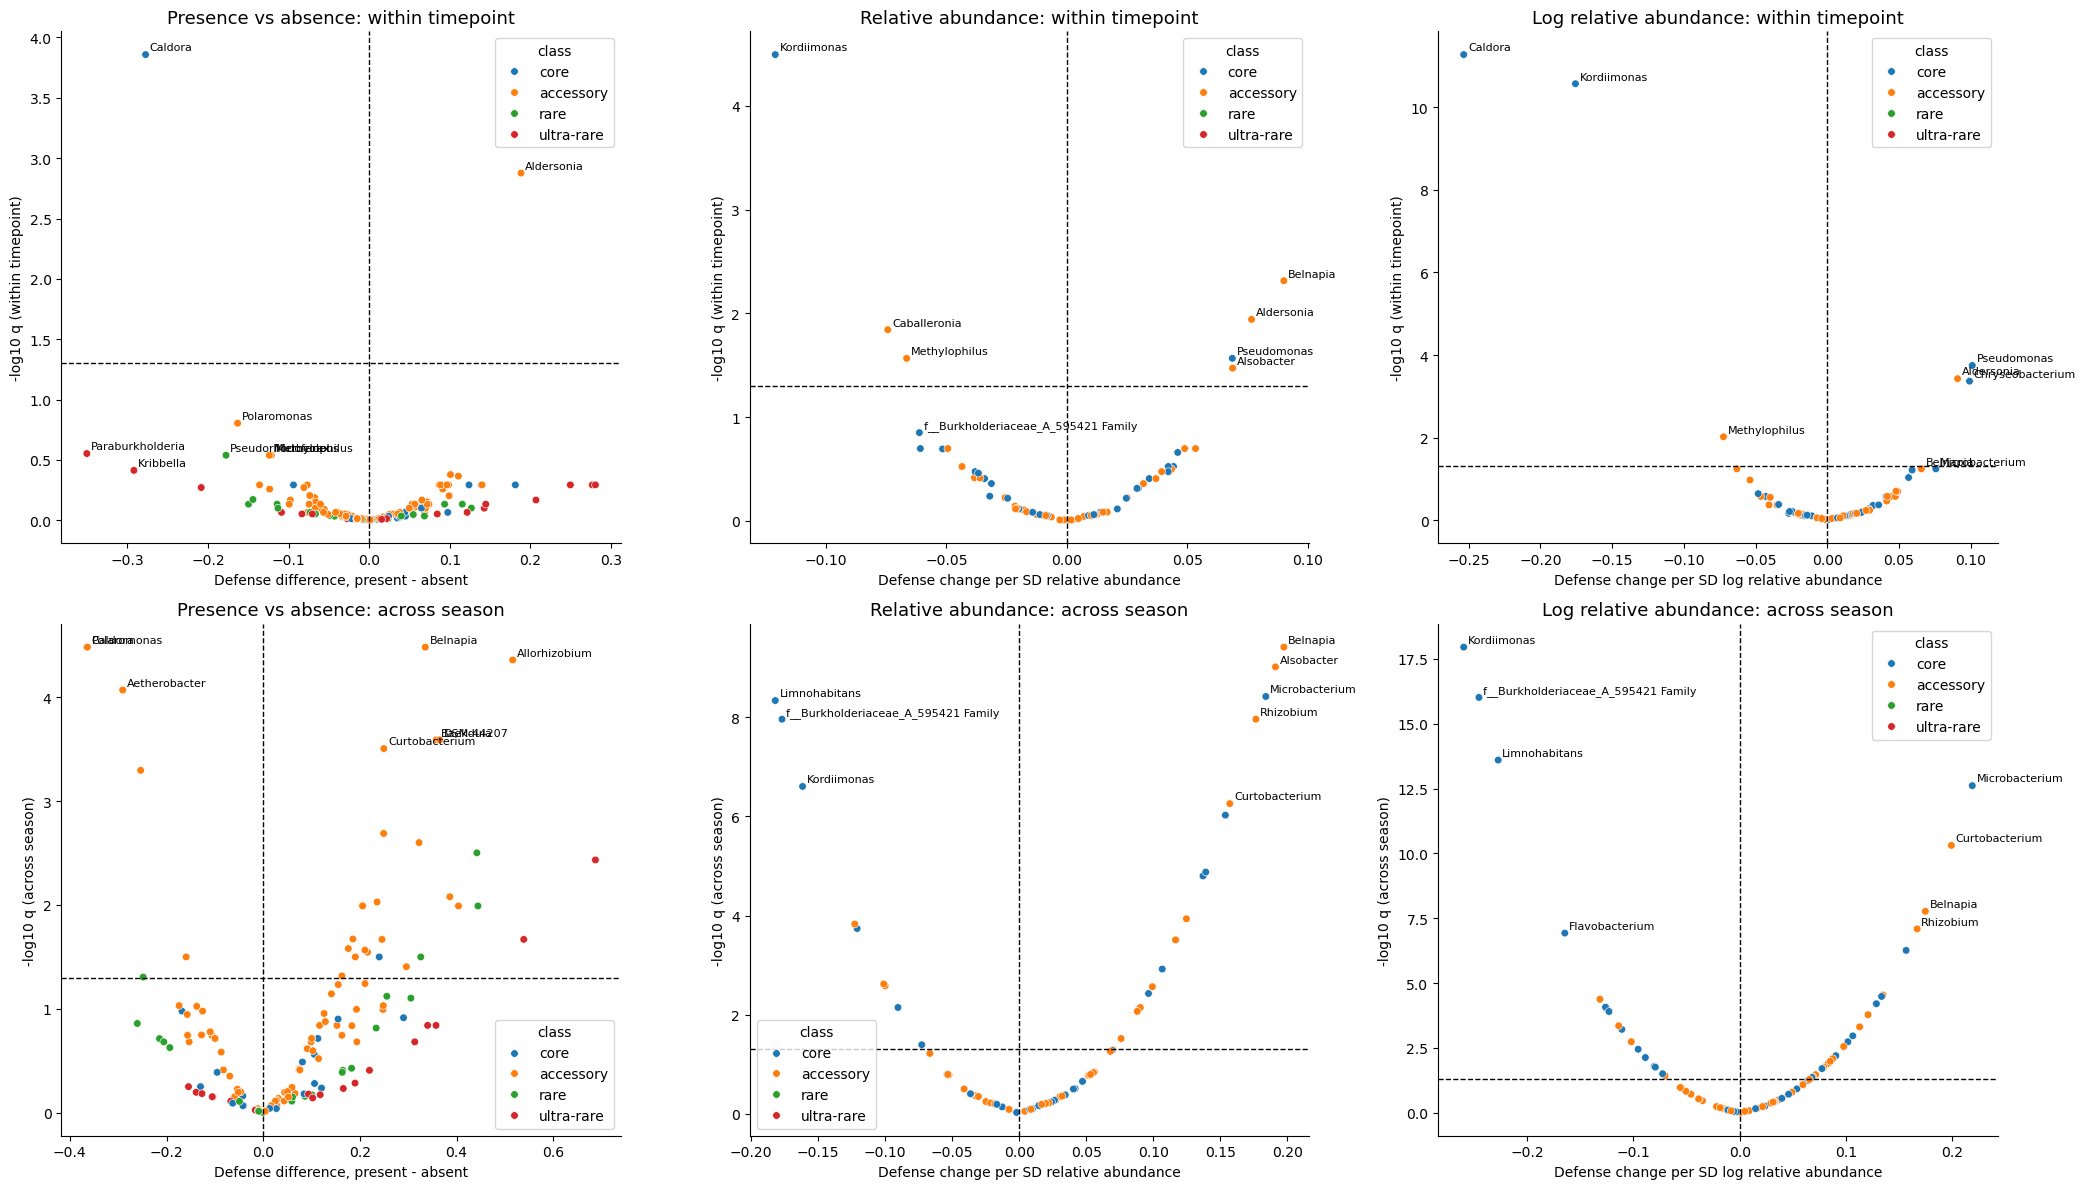

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(21, 12))
fig.patch.set_facecolor("white")
for row, mode in enumerate(["within timepoint", "across season"]):
    for col, (label, results, effect_label) in enumerate(
        [
            ("Presence vs absence", presence_results, "Defense difference, present - absent"),
            ("Relative abundance", abundance_results, "Defense change per SD relative abundance"),
            ("Log relative abundance", log_abundance_results, "Defense change per SD log relative abundance"),
        ]
    ):
        ax = axes[row, col]
        plot_df = results.assign(neg_log10_q=-np.log10(results[f"q ({mode})"].clip(lower=1e-300)))
        sns.scatterplot(
            data=plot_df,
            x=f"coef ({mode})",
            y="neg_log10_q",
            hue="class",
            hue_order=["core", "accessory", "rare", "ultra-rare"],
            s=30,
            ax=ax,
        )
        ax.axhline(-np.log10(0.05), linestyle="--", color="black", linewidth=1)
        ax.axvline(0, linestyle="--", color="black", linewidth=1)
        for genus, point in plot_df.sort_values("neg_log10_q", ascending=False).head(8).iterrows():
            ax.annotate(genus.replace("g__", ""), (point[f"coef ({mode})"], point["neg_log10_q"]), fontsize=8,
                        xytext=(3, 3), textcoords="offset points")
        ax.set_title(f"{label}: {mode}", fontsize=13)
        ax.set_xlabel(effect_label)
        ax.set_ylabel(f"-log10 q ({mode})")
        sns.despine(ax=ax)
plt.tight_layout()

In [10]:
# How the untransformed and log-transformed abundance results compare
comparison = pd.DataFrame(
    {
        f"t, {version} ({mode})": results[f"t ({mode})"]
        for version, results in abundance_results_by_version.items()
        for mode in ["within timepoint", "across season"]
    }
)
comparison["t, presence/absence (within timepoint)"] = presence_results["t (within timepoint)"].reindex(comparison.index)
print("Correlation of genus t-values between versions:")
display(comparison.corr().round(2))
for mode in ["within timepoint", "across season"]:
    sig = {
        version: set(results.index[results[f"q ({mode})"] < 0.05])
        for version, results in abundance_results_by_version.items()
    }
    print(
        f"{mode}: significant with untransformed only: {sorted(sig['Relative abundance'] - sig['Log relative abundance'])}; "
        f"log only: {sorted(sig['Log relative abundance'] - sig['Relative abundance'])}; "
        f"both: {sorted(sig['Relative abundance'] & sig['Log relative abundance'])}"
    )

Correlation of genus t-values between versions:


,"t, Relative abundance (within timepoint)","t, Relative abundance (across season)","t, Log relative abundance (within timepoint)","t, Log relative abundance (across season)","t, presence/absence (within timepoint)"
"t, Relative abundance (within timepoint)",1.00,0.50,0.85,0.50,0.61
"t, Relative abundance (across season)",0.50,1.00,0.39,0.93,0.16
"t, Log relative abundance (within timepoint)",0.85,0.39,1.00,0.49,0.85
"t, Log relative abundance (across season)",0.50,0.93,0.49,1.00,0.29
"t, presence/absence (within timepoint)",0.61,0.16,0.85,0.29,1.00


within timepoint: significant with untransformed only: ['g__Alsobacter', 'g__Belnapia', 'g__Caballeronia']; log only: ['g__Caldora', 'g__Chryseobacterium']; both: ['g__Aldersonia', 'g__Kordiimonas', 'g__Methylophilus', 'g__Pseudomonas']
across season: significant with untransformed only: ['g__Blastococcus', 'g__Geodermatophilus', 'g__Solirubrobacter']; log only: ['g__Aetherobacter', 'g__Aldersonia', 'g__Amnibacterium', 'g__Brevundimonas', 'g__Caldora', 'g__Herbiconiux', 'g__Janthinobacterium', 'g__Kineococcus', 'g__Labilithrix', 'g__Massilia', 'g__Modestobacter', 'g__Motilibacter', 'g__Pelomonas', 'g__Pseudomonas', 'g__Rugamonas', 'g__Variovorax']; both: ['f__Burkholderiaceae_A_595421 Family', 'g__Aeromicrobium', 'g__Alsobacter', 'g__Belnapia', 'g__Caulobacter', 'g__Chioneia', 'g__Chryseobacterium', 'g__Curtobacterium', 'g__Duganella', 'g__Flavobacterium', 'g__Friedmanniella', 'g__Kordiimonas', 'g__Limnohabitans', 'g__Marmoricola', 'g__Methylobacterium', 'g__Microbacterium', 'g__Microl

## 3. Pairs of genera (co-presence)

For genera present in 10–90% of samples, test samples where **both** genera are present against all other samples. For context, each pair is shown with the single-genus presence effects of its two members. A pair is only interesting if it separates defense more than either genus alone.

In [11]:
pair_genera = present.columns[
    (present.mean() >= pair_prevalence_range[0]) & (present.mean() <= pair_prevalence_range[1])
]
pair_rows = []
for genus_a, genus_b in itertools.combinations(pair_genera, 2):
    both = present[genus_a] & present[genus_b]
    if both.sum() < min_group_size or (~both).sum() < min_group_size:
        continue
    row = test_feature(both)
    row.update({"genus A": genus_a, "genus B": genus_b, "n both present": int(both.sum())})
    pair_rows.append(row)
pair_results = add_q(pd.DataFrame(pair_rows))

for mode in ["within timepoint", "across season"]:
    single_t = presence_results[f"t ({mode})"]
    pair_results[f"t genus A alone ({mode})"] = pair_results["genus A"].map(single_t)
    pair_results[f"t genus B alone ({mode})"] = pair_results["genus B"].map(single_t)
    pair_results[f"beats both singles ({mode})"] = (
        pair_results[f"t ({mode})"].abs()
        > pair_results[[f"t genus A alone ({mode})", f"t genus B alone ({mode})"]].abs().max(axis=1)
    )
pair_results.to_csv("/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_stratification_genus_pairs.csv", index=False)
print(
    f"Pairs tested: {len(pair_results)} (from {len(pair_genera)} genera); q < 0.05 within timepoint: "
    f"{(pair_results['q (within timepoint)'] < 0.05).sum()}, across season: {(pair_results['q (across season)'] < 0.05).sum()}"
)
for mode in ["within timepoint", "across season"]:
    better = (pair_results[f"q ({mode})"] < 0.05) & pair_results[f"beats both singles ({mode})"]
    print(f"Significant pairs ({mode}) that separate defense more than either genus alone: {better.sum()}")
    display(
        pair_results.sort_values(f"p ({mode})").head(15)[
            ["genus A", "genus B", "n both present", f"coef ({mode})", f"q ({mode})", f"t ({mode})",
             f"t genus A alone ({mode})", f"t genus B alone ({mode})", f"beats both singles ({mode})"]
        ].round(4)
    )

Pairs tested: 3394 (from 84 genera); q < 0.05 within timepoint: 27, across season: 863
Significant pairs (within timepoint) that separate defense more than either genus alone: 8


,genus A,genus B,n both present,coef (within timepoint),q (within timepoint),t (within timepoint),t genus A alone (within timepoint),t genus B alone (within timepoint),beats both singles (within timepoint)
524,g__Aldersonia,g__Microbacterium,133,0.2240,0.0015,5.0382,4.3397,1.7457,True
535,g__Aldersonia,g__Pigmentiphaga,88,0.2568,0.0015,4.9974,4.3397,2.0652,True
541,g__Aldersonia,g__Rathayibacter,104,0.2327,0.0022,4.8411,4.3397,1.3752,True
510,g__Aldersonia,g__Hylemonella,115,0.2250,0.0023,4.7617,4.3397,0.7738,True
518,g__Aldersonia,g__Marmoricola,104,0.2164,0.0056,4.5124,4.3397,0.7857,True
401,g__Agrobacterium,g__Aldersonia,136,0.1974,0.0056,4.4832,1.8488,4.3397,True
497,g__Aldersonia,g__Curvibacter,63,0.2606,0.0103,4.3062,4.3397,1.1507,False
486,g__Aldersonia,g__Blastococcus,107,0.2027,0.0112,4.2572,4.3397,1.2407,False
1496,g__Caldora,g__Rhodopseudomonas,251,-0.2138,0.0127,-4.1721,-4.9834,-0.2119,False
530,g__Aldersonia,g__Patulibacter,134,0.1864,0.0127,4.1590,4.3397,0.9976,False


Significant pairs (across season) that separate defense more than either genus alone: 404


,genus A,genus B,n both present,coef (across season),q (across season),t (across season),t genus A alone (across season),t genus B alone (across season),beats both singles (across season)
922,g__Baekduia,g__Curtobacterium,44,0.5783,0.0,6.3017,4.4208,4.3464,True
1735,g__Curtobacterium,g__Rhizobium,73,0.4639,0.0,6.2549,4.3464,3.8389,True
636,g__Amnibacterium,g__Belnapia,85,0.4288,0.0,6.1190,2.1190,5.0417,True
965,g__Baekduia,g__Rhizobium,24,0.7328,0.0,6.0294,4.4208,3.8389,True
988,g__Belnapia,g__Curtobacterium,69,0.4565,0.0,5.9969,5.0417,4.3464,True
944,g__Baekduia,g__Methylibium,40,0.5666,0.0,5.8854,4.4208,1.7083,True
999,g__Belnapia,g__Herbiconiux,38,0.5788,0.0,5.8748,5.0417,3.3208,True
911,g__Baekduia,g__Belnapia,34,0.6063,0.0,5.8491,4.4208,5.0417,True
1035,g__Belnapia,g__Rhizobium,40,0.5619,0.0,5.8325,5.0417,3.8389,True
251,g__Aeromicrobium,g__Belnapia,91,0.3899,0.0,5.6739,2.0412,5.0417,True


## 4. Combinations, data-driven: decision tree and random forest

Features: relative abundance (% of reads) of genera present in ≥ 10% of samples, plus the group features from section 1. Tree splits are therefore thresholds in % of reads.

Targets: the defense score with timepoint means removed (within timepoint), and the raw defense score (across season).

Models are evaluated with cross-validation that holds out whole timepoints (`GroupKFold`): the model always predicts samples from timepoints it hasn't seen. They're compared with the same models fitted to shuffled defense scores (`n_permutations`), shuffled within timepoint for the within-timepoint target and across all samples for the across-season target. If the real cross-validated R² isn't above the shuffled ones, the microbiome doesn't predict defense beyond chance.

In [12]:
model_genera = present.columns[present.mean() >= 0.1]
model_features = pd.concat([sample_genera[model_genera], group_features], axis=1)
model_features.columns = [str(c) for c in model_features.columns]
group_kfold = GroupKFold(n_splits=6)
rng = np.random.default_rng(random_seed)


def cv_r2(model, target):
    predicted = cross_val_predict(model, model_features, target, cv=group_kfold, groups=timepoints)
    return r2_score(target, predicted)


def shuffle_target(target, mode):
    if mode == "within timepoint":
        return target.groupby(timepoints).transform(lambda v: rng.permutation(v.to_numpy()))
    return pd.Series(rng.permutation(target.to_numpy()), index=target.index)


models = {
    "Decision tree (depth 3)": lambda: DecisionTreeRegressor(max_depth=3, min_samples_leaf=15, random_state=random_seed),
    "Random forest": lambda: RandomForestRegressor(
        n_estimators=200, min_samples_leaf=5, max_features=0.3, n_jobs=-1, random_state=random_seed
    ),
}
targets = defense_versions

cv_rows = []
null_r2 = {}
for model_name, make_model in models.items():
    for target_name, target in targets.items():
        real = cv_r2(make_model(), target)
        n_perm = n_permutations if "tree" in model_name.lower() else max(20, n_permutations // 5)
        null = np.array([cv_r2(make_model(), shuffle_target(target, target_name)) for _ in range(n_perm)])
        null_r2[(model_name, target_name)] = null
        cv_rows.append(
            {
                "model": model_name,
                "target": target_name,
                "cross-validated R2": real,
                "shuffled R2 (median)": np.median(null),
                "shuffled R2 (95th pct)": np.percentile(null, 95),
                "permutation p": (1 + (null >= real).sum()) / (1 + len(null)),
                "permutations": len(null),
            }
        )
cv_results = pd.DataFrame(cv_rows)
cv_results.round(3)

,model,target,cross-validated R2,shuffled R2 (median),shuffled R2 (95th pct),permutation p,permutations
0,Decision tree (depth 3),within timepoint,-0.083,-0.129,-0.061,0.158,100
1,Decision tree (depth 3),across season,0.087,-0.146,-0.080,0.010,100
2,Random forest,within timepoint,0.119,-0.026,-0.007,0.048,20
3,Random forest,across season,0.327,-0.046,-0.002,0.048,20


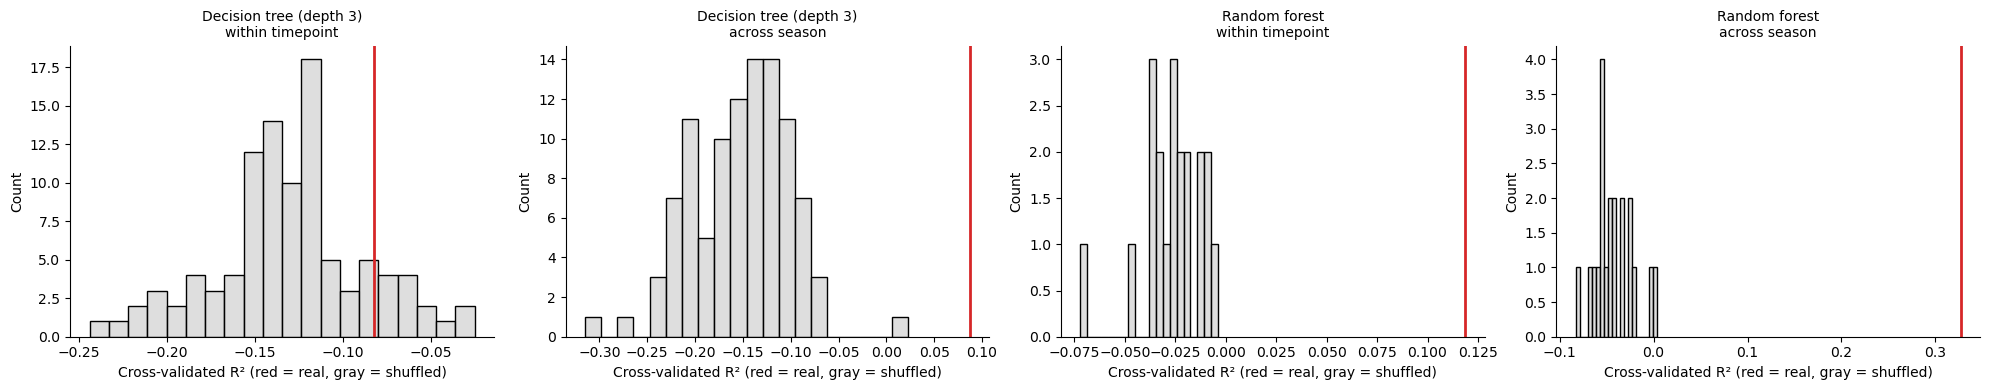

In [13]:
fig, axes = plt.subplots(1, len(null_r2), figsize=(5 * len(null_r2), 4))
fig.patch.set_facecolor("white")
for ax, ((model_name, target_name), null) in zip(axes, null_r2.items()):
    real = cv_results.loc[
        (cv_results["model"] == model_name) & (cv_results["target"] == target_name), "cross-validated R2"
    ].iloc[0]
    sns.histplot(null, bins=20, color="lightgray", ax=ax)
    ax.axvline(real, color="tab:red", linewidth=2)
    ax.set_title(f"{model_name}\n{target_name}", fontsize=10)
    ax.set_xlabel("Cross-validated R² (red = real, gray = shuffled)")
    sns.despine(ax=ax)
plt.tight_layout()

In [14]:
# Random forest feature importance (impurity importance, fitted on all samples)
importance_tables = {}
for target_name, target in targets.items():
    forest = models["Random forest"]().fit(model_features, target)
    importance_tables[target_name] = pd.Series(forest.feature_importances_, index=model_features.columns)
importance = pd.DataFrame(importance_tables).sort_values("within timepoint", ascending=False)
importance.head(20).round(4)

,within timepoint,across season
g__Kordiimonas,0.0665,0.1361
g__Caldora,0.0621,0.0315
g__Aldersonia,0.0550,0.0092
g__Pseudomonas,0.0406,0.0192
g__Chryseobacterium,0.0394,0.0541
g__Klenkia,0.0241,0.0072
g__Methylophilus,0.0221,0.0017
g__Ramlibacter,0.0220,0.0072
g__Alsobacter,0.0196,0.0134
f__Burkholderiaceae_A_595421 Family,0.0192,0.1080



Tree strata (within timepoint):


,count,mean,std
leaf,,,
9,15,-0.410,0.271
8,226,-0.081,0.296
11,47,-0.021,0.324
3,65,0.005,0.360
12,35,0.205,0.274
4,21,0.367,0.420
5,15,0.685,0.805



Tree strata (across season):


,count,mean,std
leaf,,,
5,219,-0.250,0.361
8,126,0.079,0.464
4,37,0.100,0.406
7,21,0.629,0.478
1,21,1.266,1.237


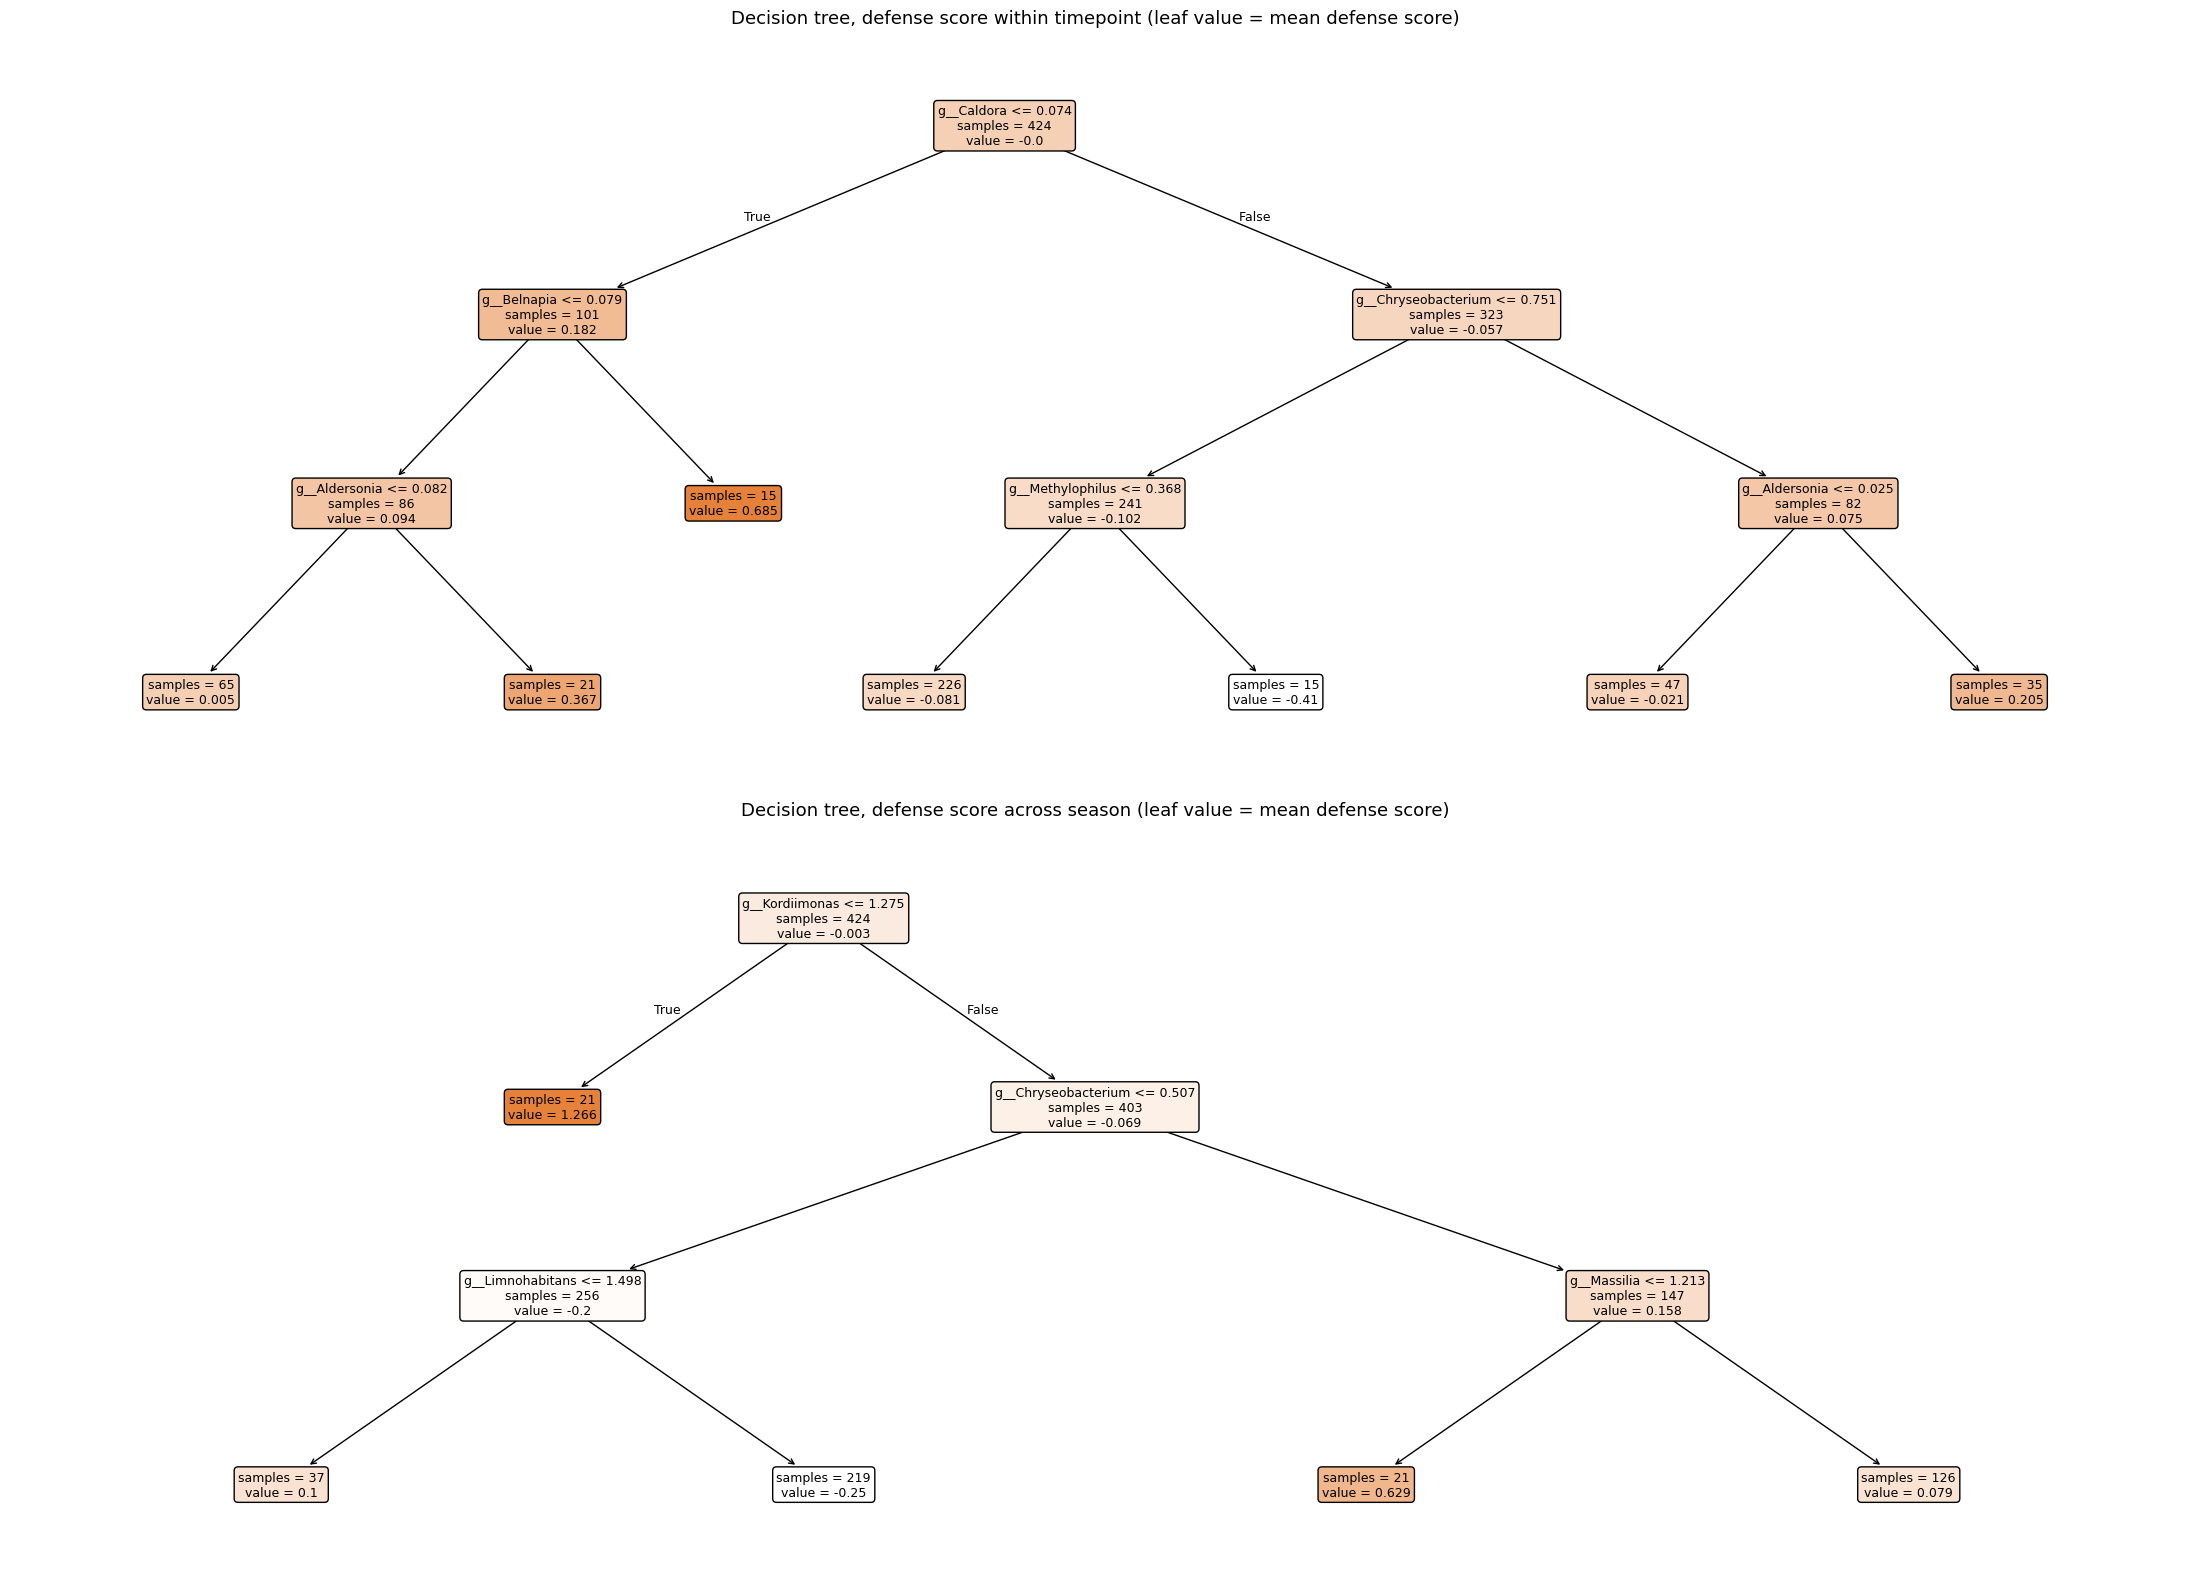

In [15]:
# The decision tree fitted on all samples: each leaf is a microbiome-defined stratum
fig, axes = plt.subplots(2, 1, figsize=(22, 16))
fig.patch.set_facecolor("white")
tree_strata = {}
for ax, (target_name, target) in zip(axes, targets.items()):
    tree = models["Decision tree (depth 3)"]().fit(model_features, target)
    plot_tree(tree, feature_names=model_features.columns, filled=True, rounded=True, fontsize=9, ax=ax, impurity=False)
    ax.set_title(f"Decision tree, defense score {target_name} (leaf value = mean defense score)", fontsize=13)
    leaves = pd.Series(tree.apply(model_features), index=samples)
    tree_strata[target_name] = (
        pd.DataFrame({"leaf": leaves, "defense": target})
        .groupby("leaf")["defense"]
        .agg(["count", "mean", "std"])
        .sort_values("mean")
    )
plt.tight_layout()
for target_name, strata in tree_strata.items():
    print(f"\nTree strata ({target_name}):")
    display(strata.round(3))